# Survey of single-cell data integration benchmarking

In [1]:
import pandas as pd
import numpy as np
from upsetplot import plot, from_contents, UpSet
import matplotlib.pyplot as plt
import networkx as nx
import circlify
import squarify
import random

import matplotlib.font_manager as font_manager
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()


import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

def truncate_colormap(cmap_name, minval=0.0, maxval=1.0, n=100):
    cmap = plt.get_cmap(cmap_name)
    new_colors = cmap(np.linspace(minval, maxval, n))
    return mcolors.LinearSegmentedColormap.from_list(
        f'trunc({cmap_name},{minval:.2f},{maxval:.2f})', new_colors
    )

trimmed_blues = truncate_colormap('Blues', 0.1, 0.7)
plt.colormaps.register(cmap=trimmed_blues)
trimmed_reds = truncate_colormap('Reds', 0.0, 0.5)
plt.colormaps.register(cmap=trimmed_reds)

In [2]:
import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

## Method comparison popularity

Which methods are most commonly benchmarked against

In [3]:
df = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=2)
benchmark_info = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=5)[['Benchmark', 'Year published']]

df = df[['Method', 'Comparison']]

In [4]:
# Which methods are not in our benchmark info
# These are basically all non-integration methods
# (Or at least they do not make any claims about batch correction.)
set(benchmark_info['Benchmark']).difference(df['Method'])

{'CIDR',
 'CSN',
 'CellAssign',
 'CellPLM',
 'ComBat',
 'DCA',
 'DCA + ComBat',
 'DeepImpute',
 'DeepSEM',
 'FastMNN',
 'GLUE',
 'LAmbDA',
 'LDVAE',
 'MAGAN',
 'MAGIC',
 'MARIO',
 'MARS',
 'MINT',
 'MIRA',
 'Monocle-louvain',
 'PRPS',
 'QuantNorm',
 'RPCA',
 'RSS',
 'RaceID',
 'SATURN',
 'SAVER',
 'SAVER-X',
 'SC3',
 'SCEA',
 'SCENIC',
 'SIMLR',
 'SINCERA',
 'SSRE',
 'VEGA',
 'ZIFA',
 'ZINB-WaVE',
 'contrastive-sc',
 'glmPCA',
 'graph-sc',
 'limma',
 'netNMF-sc',
 'online-iNMF',
 'scArches',
 'scBERT',
 'scDCC',
 'scDHA',
 'scDSSC',
 'scDeepCluster',
 'scDeepSort',
 'scFoundation',
 'scGAE',
 'scGCN',
 'scGen',
 'scIGANs',
 'scImpute',
 'scMGCA',
 'scNAME',
 'scRAE',
 'scSemiGAN',
 'scTab',
 'scmap',
 'scvis',
 'ssGSEA',
 'trVAE'}

In [5]:
set(df['Comparison']).difference(benchmark_info['Benchmark'])

set()

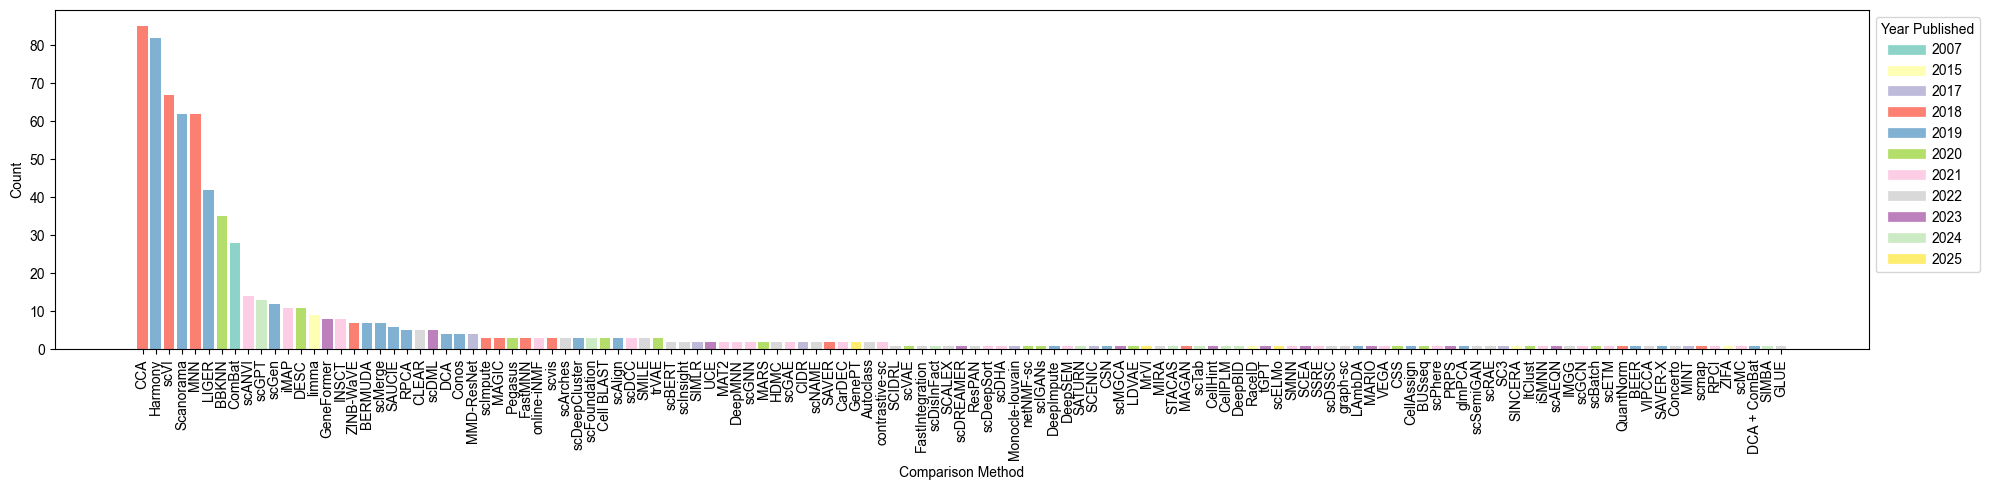

In [6]:
from matplotlib.colors import to_hex
counts = df['Comparison'].value_counts().reset_index()
counts.columns = ['Comparison', 'Count']

counts = counts.merge(benchmark_info, left_on='Comparison', right_on='Benchmark')
counts = counts.sort_values('Count', ascending=False)
counts = counts[~counts['Year published'].isna()]
counts['Year published'] = counts['Year published'].astype(int)


unique_years = sorted(counts['Year published'].unique())
cmap = plt.get_cmap('Set3')
set3_hex = [to_hex(cmap(i)) for i in range(12)]
del set3_hex[5]
year_to_color = {year: set3_hex[i] for i, year in enumerate(unique_years)}

# Apply the mapping to the counts dataframe
bar_colors = [year_to_color[y] for y in counts['Year published']]

with plt.rc_context({'figure.figsize': (20, 5)}):
    bars = plt.bar(counts['Comparison'], counts['Count'], color=bar_colors)
    plt.xlabel("Comparison Method")
    plt.ylabel("Count")
    plt.xticks(rotation=90)
    
    # 4. Create a custom legend for the Years
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], color=year_to_color[year], lw=7, label=year) 
                       for year in unique_years]
    plt.legend(handles=legend_elements, title="Year Published", 
               bbox_to_anchor=(1.0, 1), loc='upper left', ncol=1)
    
    plt.tight_layout()
    plt.show()

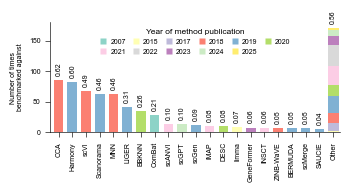

In [86]:
threshold = 5
mask = counts['Count'] > threshold
keep_df = counts[mask].copy()
other_df = counts[~mask].copy()

other_stacked = other_df.groupby('Year published')['Count'].sum().reset_index()

fig, ax = plt.subplots(1, 1, figsize=(3.6, 2))

main_colors = [year_to_color[y] for y in keep_df['Year published']]
plt.bar(keep_df['Comparison'], keep_df['Count'], color=main_colors, width=0.7)

bottom_val = 0
other_x_label = "Other"
for _, row in other_stacked.iterrows():
    year = row['Year published']
    count = row['Count']
    plt.bar(other_x_label, count, bottom=bottom_val, color=year_to_color[year])
    bottom_val += count

plt.ylabel("Number of times\nbenchmarked against", fontsize=5)
plt.xticks(rotation=90)

# Labels for percentages (using your total N logic from before)
total_n = df['Method'].nunique()
for i, p in enumerate(ax.patches):
    height = p.get_height()
    if height > 0 and i < 20:
        # Calculate center of the specific segment/bar
        y_pos = p.get_y() + height
        ax.annotate(f'{height / total_n:.2f}', 
                    (p.get_x() + p.get_width() / 2., y_pos), 
                    ha='center', va='bottom', xytext=(0, 3), 
                    textcoords='offset points', fontsize=5, rotation=90)
    if i == len(ax.patches) - 1:
        y_pos = p.get_y() + height
        ax.annotate(f'0.56', 
                    (p.get_x() + p.get_width() / 2., y_pos), 
                    ha='center', va='bottom', xytext=(0, 3), 
                    textcoords='offset points', fontsize=5, rotation=90)

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="s",  # 's' makes it a square
        color="none",  # Removes the connecting line
        markerfacecolor=year_to_color[year],
        markeredgecolor="none",
        markersize=4,  # Adjust this to change square size
        label=year,
    )
    for year in unique_years
]

reordered_elements = []
for i in range(6):
    reordered_elements.append(legend_elements[i])
    if i + 6 < 11:
        reordered_elements.append(legend_elements[i + 6])

plt.legend(
    handles=reordered_elements,
    title="Year of method publication",
    bbox_to_anchor=(0.5, 1),
    loc="upper center",
    ncols=6,
    fontsize=5,
    title_fontsize=6,
    handlelength=1.0,
    handleheight=1.0,
    handletextpad=0.5,
    columnspacing=1.0,
    frameon=False
)

plt.xlim(-.6, 20.5)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='both', labelsize=5, width=.45)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.tight_layout()
plt.savefig('../publication_figures/comparison_methods_bar.svg', dpi=300, bbox_inches='tight')
plt.show()

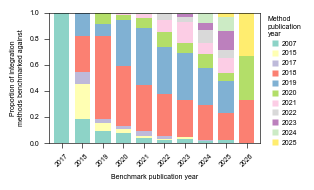

In [8]:
df_merged = df.merge(benchmark_info, left_on='Method', right_on='Benchmark')
df_merged = df_merged.rename({'Year published': 'Method Year'}, axis=1).drop(columns=['Benchmark'])

df_merged = df_merged.merge(benchmark_info, left_on='Comparison', right_on='Benchmark')
df_merged = df_merged.rename(columns={'Year published': 'Comparison Year'}).drop(columns=['Benchmark'])

plot_data = df_merged.groupby(['Method Year', 'Comparison Year']).size().unstack(fill_value=0)
plot_data = plot_data.sort_index().sort_index(axis=1)

plot_data_percent = plot_data.div(plot_data.sum(axis=1), axis=0)
plot_data_percent.index = plot_data_percent.index.astype(int)
plot_data_percent.columns = plot_data_percent.columns.astype(int)

ax = plot_data_percent.plot(kind='bar', stacked=True, figsize=(3.25, 2), colormap='Set3', width=0.75)
for i, container in enumerate(ax.containers):
    labels = plot_data.iloc[:, i].astype(int)
    labels = [str(v) if v > 0 else "" for v in labels]
#     ax.bar_label(container, labels=labels, label_type='center', color='black', fontweight='bold')


handles, labels = ax.get_legend_handles_labels()

custom_handles = [
    Line2D(
        [0],
        [0],
        marker="s",
        color="none",
        markerfacecolor=h.patches[0].get_facecolor(),
        markeredgecolor="none",
        markersize=4,  # Adjust this to change square size
    )
    for h in handles
]

# 3. Draw the legend with the custom shrunk squares
plt.legend(
    handles=custom_handles,
    labels=labels,
    title="Method\npublication\nyear",
    bbox_to_anchor=(1.01, 1.02),
    loc="upper left",
    fontsize=5,
    title_fontsize=5,
    handlelength=1.0,
    handleheight=1.0,
    handletextpad=0.5,
    frameon=False
)


plt.xlabel('Benchmark publication year', fontsize=5)
plt.ylabel('Proportion of integration\nmethods benchmarked against', fontsize=5)
plt.xticks(rotation=45)
ax.tick_params(axis='both', labelsize=5, width=.45)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('../publication_figures/comparison_year_stacked_bar.svg', dpi=300, bbox_inches='tight')
plt.show()

## Dataset popularity

Which datasets are most commonly used? Also shown is the inconsistency in application of Pancreas data

In [65]:
df = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=1)
df['Paper'] = df['Dataset First Author'] + '_' + df['Dataset Year'].fillna(0).astype(int).astype(str) +'_'+ df['Dataset Journal'].fillna('')

benchmark_info = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=5)[['Benchmark', 'Year published']]

In [66]:
len(df['Paper'].dropna().unique())

274

In [67]:
# Dataset publication year over method year
df_merged = df.merge(benchmark_info, left_on='Method', right_on='Benchmark')
df_merged = df_merged.rename({'Year published': 'Method Year'}, axis=1).drop(columns=['Benchmark'])
df_merged['Method Year'] = df_merged['Method Year'].astype(int)
df_merged = df_merged[~df_merged["Dataset Year"].isna()]
df_merged['Dataset Year'] = df_merged['Dataset Year'].astype(int)

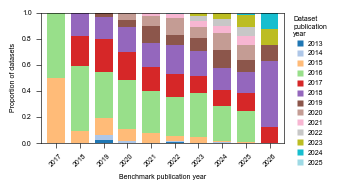

In [68]:
plot_data = df_merged.groupby(['Method Year', 'Dataset Year']).size().unstack(fill_value=0)
plot_data = plot_data.sort_index().sort_index(axis=1)

plot_data_percent = plot_data.div(plot_data.sum(axis=1), axis=0)

plot_data_percent.index = plot_data_percent.index.astype(int)
plot_data_percent.columns = plot_data_percent.columns.astype(int)


ax = plot_data_percent.plot(kind='bar', stacked=True, figsize=(3.5, 2), colormap='tab20', width=0.75)
for i, container in enumerate(ax.containers):
    labels = plot_data.iloc[:, i].astype(int)
    labels = [str(v) if v > 0 else "" for v in labels]
#     ax.bar_label(container, labels=labels, label_type='center', color='black', fontweight='bold')

plt.xlabel('Benchmark publication year', fontsize=5)
plt.ylabel('Proportion of datasets', fontsize=5)

handles, labels = ax.get_legend_handles_labels()

custom_handles = [
    Line2D(
        [0],
        [0],
        marker="s",
        color="none",
        markerfacecolor=h.patches[0].get_facecolor(),
        markeredgecolor="none",
        markersize=4,  # Adjust this to change square size
    )
    for h in handles
]

plt.legend(
    handles=custom_handles,
    labels=labels,
    title="Dataset\npublication\nyear",
    bbox_to_anchor=(1.01, 1.02),
    loc="upper left",
    fontsize=5,
    title_fontsize=5,
    handlelength=1.0,
    handleheight=1.0,
    handletextpad=0.5,
    frameon=False
)

ax.tick_params(axis='both', labelsize=5, width=.45)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('../publication_figures/dataset_year_stacked_bar.svg', dpi=300, bbox_inches='tight')
plt.show()

In [69]:
plot_data

Dataset Year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Method Year,,,,,,,,,,,,,
2017,0,0,1,1,0,0,0,0,0,0,0,0,0
2018,0,0,2,11,5,4,0,0,0,0,0,0,0
2019,2,3,11,29,21,14,3,0,0,0,0,0,0
2020,0,1,7,27,16,14,4,4,0,0,0,0,0
2021,0,0,12,49,27,29,19,12,3,1,0,0,0
2022,1,2,8,63,38,46,16,28,7,0,0,0,2
2023,0,0,9,66,24,38,19,16,9,8,4,0,1
2024,0,1,1,38,17,24,19,18,8,7,7,0,0
2025,0,0,1,35,20,24,14,16,10,11,13,1,2


In [70]:
df['Paper'].value_counts().head(20)

Paper
Baron_2016_Cell Systems                66
Muraro_2016_Cell Systems               65
Segerstolpe_2016_Cell Metabolism       61
Lawlor_2017_Genome Research            43
Grun_2016_Cell Stem Cell               41
Tabula Muris Consortium_2018_Nature    37
Villani_2017_Science                   30
Xin_2016_Cell Metabolism               29
Zheng_2017_Nature Communications       27
Han_2018_Cell                          19
Zappia_2017_Genome Biology             17
Shekhar_2016_Cell                      16
10X Genomics PBMC 10k_2018_            16
Saunders_2018_Cell                     15
Wang_2016_Diabetes                     15
Vieira Braga_2019_Nature Medicine      15
Freytag_2018_F1000 Research            15
Sun_2019_Nature Communications         15
Oetjen_2018_JCI Insight                15
Paul_2015_Cell                         14
Name: count, dtype: int64

In [71]:
pancreas = df[df.Paper.isin(['Baron_2016_Cell Systems', 'Muraro_2016_Cell Systems', 'Lawlor_2017_Genome Research', 'Xin_2016_Cell Metabolism', 'Segerstolpe_2016_Cell Metabolism',
                             'Grun_2016_Cell Stem Cell', 'Wang_2016_Diabetes', 'Xin_2018_Diabetes', 'Enge_2017_Cell'])]
pancreas

,Method,Dataset First Author,Dataset Year,Dataset Journal,Notes,Paper
1,AIF,Muraro,2016.0,Cell Systems,NaN,Muraro_2016_Cell Systems
2,AIF,Segerstolpe,2016.0,Cell Metabolism,NaN,Segerstolpe_2016_Cell Metabolism
3,AIF,Xin,2016.0,Cell Metabolism,NaN,Xin_2016_Cell Metabolism
4,AIF,Wang,2016.0,Diabetes,NaN,Wang_2016_Diabetes
5,AIF,Baron,2016.0,Cell Systems,Human pancreas cells,Baron_2016_Cell Systems
...,...,...,...,...,...,...
1017,Concerto,Lawlor,2017.0,Genome Research,NaN,Lawlor_2017_Genome Research
1018,Concerto,Grun,2016.0,Cell Stem Cell,NaN,Grun_2016_Cell Stem Cell
1019,Concerto,Muraro,2016.0,Cell Systems,NaN,Muraro_2016_Cell Systems
1025,scANVI,Baron,2016.0,Cell Systems,NaN,Baron_2016_Cell Systems


In [72]:
pancreas['Paper'] = pancreas['Paper'].replace({
    'Baron_2016_Cell Systems': 'Baron',
    'Muraro_2016_Cell Systems': 'Muraro',
    'Lawlor_2017_Genome Research': 'Lawlor',
    'Xin_2016_Cell Metabolism': "Xin (2016)",
    'Segerstolpe_2016_Cell Metabolism': 'Segerstolpe',
    'Grun_2016_Cell Stem Cell': 'Grun',
    'Wang_2016_Diabetes': "Wang",
    'Xin_2018_Diabetes': 'Xin (2018)',
    'Enge_2017_Cell': "Enge"
})

/tmp/ipykernel_2898801/1838084520.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pancreas['Paper'] = pancreas['Paper'].replace({


/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/metacell_env/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/metacell_env/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to p

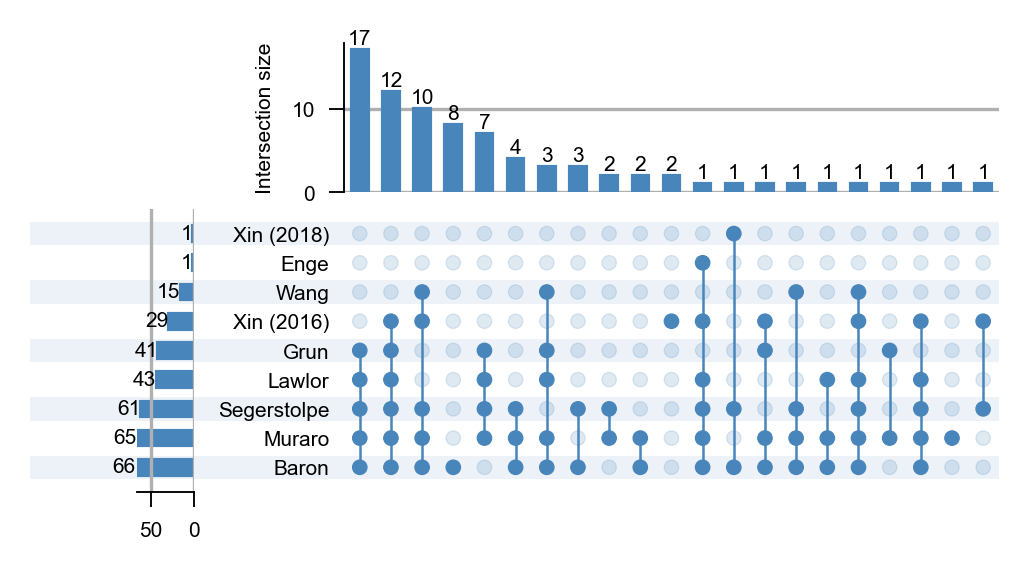

In [75]:
from matplotlib.collections import PathCollection, LineCollection

contents = pancreas.groupby('Paper')['Method'].apply(list).to_dict()
data = from_contents(contents)
with plt.rc_context({'figure.dpi': 300}):
    fig = plt.figure(figsize=(1.6, 1.6))
    upset = UpSet(
        data,
        subset_size='count',
        show_counts='%d',
        sort_by='cardinality',
        sort_categories_by='cardinality',
        facecolor="#4885BB",
        shading_color=0.1,
        element_size=10,   # was 20 — try 8–12 for a small figure
        intersection_plot_elements=5,  # default 6; shrinks bar-chart height relative to matrix
        totals_plot_elements=2,
    )

    fig_dict = upset.plot(fig=fig)
    
    ax_matrix = fig_dict['matrix']
    ax_intersections = fig_dict['intersections']
    ax_totals = fig_dict['totals']
    
    ax_matrix.tick_params(axis='both', labelsize=5, width=.45)
    for spine in ax_matrix.spines.values():
        spine.set_linewidth(0.45)
        
    ax_intersections.tick_params(axis='both', labelsize=5, width=.45)
    for spine in ax_intersections.spines.values():
        spine.set_linewidth(0.45)
        
    ax_totals.tick_params(axis='both', labelsize=5, width=.45)
    for spine in ax_totals.spines.values():
        spine.set_linewidth(0.45)
    
    ax_intersections.set_ylabel(ax_intersections.get_ylabel(), fontsize=5)
    
    for text in ax_intersections.texts:
        text.set_fontsize(5)
    for text in ax_totals.texts:
        text.set_fontsize(5)
        

    for coll in ax_matrix.collections:
        if isinstance(coll, PathCollection):
            coll.set_sizes([12])
            coll.set_linewidth(0.3)
        elif isinstance(coll, LineCollection):
            coll.set_linewidth(0.6)

    # Shrink the vertical connector lines
    for line in ax_matrix.lines:
        line.set_linewidth(0.6)

    plt.tight_layout()
    
    pos_matrix = ax_matrix.get_position()
    pos_totals = ax_totals.get_position()

    gap = 0.12  # tune this — smaller = tighter
    new_totals_x0 = pos_matrix.x0 - pos_totals.width - gap

    ax_totals.set_position([new_totals_x0, pos_totals.y0, pos_totals.width, pos_totals.height])
    
    plt.savefig('../publication_figures/pancreas_upset.svg', bbox_inches='tight')
    plt.show()

In [24]:
data.loc[True, False, True, True].sort_index()

/tmp/ipykernel_825686/1427629495.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  data.loc[True, False, True, True].sort_index()


id
Segerstolpe Wang  Xin (2016) Xin (2018)               
False       False False      False             corralm
True        False True       False          Cell BLAST
                             False              GenePT
                             False             inClust
                             False               INSCT
                             False             scCRAFT
                             False           scDREAMER
                             False       scInterpreter
                             False             scPRINT
                             False              STACAS
                             False              TOSICA
                             False                scIB
                             False         YiBenchmark
            True  True       False             scMerge

In [67]:
# How many datasets each method uses
df.Method.value_counts().value_counts(sort=False)

count
24     1
23     1
21     1
19     1
18     1
17     2
15     4
14     5
13     4
12     3
11     7
10     6
9      8
8      5
7     10
6     10
5     14
4     12
3      9
2      9
1      5
Name: count, dtype: int64

In [10]:
benchmark_info['Benchmark'].nunique()

202

In [288]:
df.Method.value_counts()

Method
SCALEX         24
scMerge        23
STACAS         21
GLOBE          19
scCRAFT        18
               ..
DeepAdapter     1
scPhere         1
Pegasus         1
MrVI            1
scVAE           1
Name: count, Length: 134, dtype: int64

## Metric popularity

In [87]:
df = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=0)

In [88]:
freq = df['Metric'].value_counts().dropna()

In [89]:
mask = freq < 4
main_counts = freq[~mask]
other_sum = freq[mask].sum()

# 4. Add the "Other" category if it contains any values
if other_sum > 0:
    # Use pd.Series and pd.concat to merge them
    other_series = pd.Series({'OTHER': other_sum})
    plot_data = pd.concat([main_counts, other_series])
else:
    plot_data = main_counts

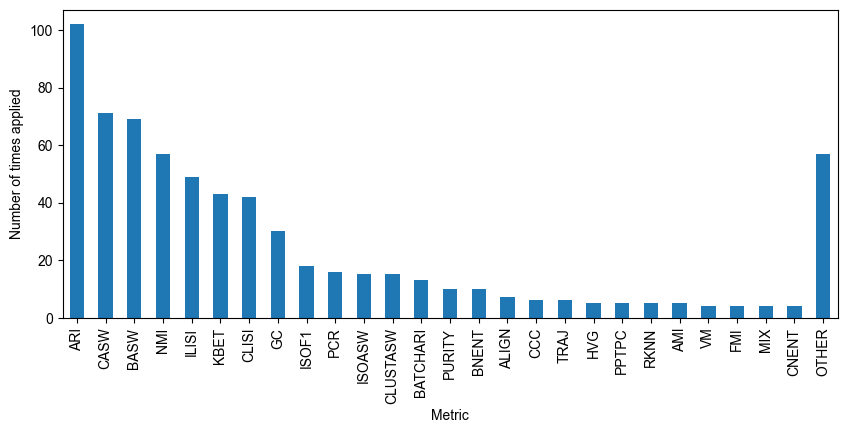

In [90]:
with plt.rc_context({'figure.figsize': (10, 4)}):
    plot_data.plot(kind="bar")
    plt.xlabel("Metric")
    plt.ylabel("Number of times applied")
    plt.show()
    # Need to color bars by whether they are used in benchmark Tran or Luecken

In [91]:
targets = ['ARI', 'NMI']
filtered_df = df[df['Metric'].isin(targets)]

# 2. Group by Method and get the unique metrics for each
# We use set() so we can do easy comparisons
method_metrics = filtered_df.groupby('Method')['Metric'].apply(set)

# 3. Calculate the counts based on your specific requirements
count_both = sum(metrics == {'ARI', 'NMI'} for metrics in method_metrics)
count_ari_only = sum(metrics == {'ARI'} for metrics in method_metrics)
count_nmi_only = sum(metrics == {'NMI'} for metrics in method_metrics)

print(f"Methods with both ARI & NMI: {count_both}")
print(f"Methods with ARI (and no NMI): {count_ari_only}")
print(f"Methods with NMI (and no ARI): {count_nmi_only}")

Methods with both ARI & NMI: 56
Methods with ARI (and no NMI): 46
Methods with NMI (and no ARI): 1


In [92]:
bio = ['agree', 'ami', 'ari', 'arif', 'awc', 'bami', 'bari', 'bvm', 'casw', 'ccc', 'cch', 'ccent', 'clustch', 'clisi', 'clustasw', 'clustdbi',
       'cnent', 'comp', 'compact', 'corrmse', 'cdbi', 'f1', 'fknn', 'flogreg', 'fmi', 'homo', 'isoasw', 'isof1',
       'jacc', 'ksim', 'ldfdiff', 'mcc', 'modularity', 'morani', 'nmi', 'nmif', 'nnmap', 'ocs', 'purity', 'rknn',
       'scgraph', 'separation', 'traj', 'vi', 'vm', 
       'aic', 'hvg', 'jsd',]
batch = ['adgbd', 'align', 'basw', 'batchari', 'bcent', 'bknn', 'blogreg', 'bnent', 'bp', 'bras', 'cre', 'cilisi', 'csms', 'gc', 'ilisi',  'kbet', 'kbetall',
         'kldiv', 'embdiv', 'mix', 'pcr', 'pptpc', 'probe', 'pstdb', 'sv',
         'batchami', 'batchnmi', 'bcef', 'cov', 'fvalue', 'klc', 'procrustes', 'sauciemix', 'anovaf']
len(bio), len(batch)

(48, 34)

In [93]:
set(df['Metric'].str.lower().unique()).difference(bio+batch)

{nan}

In [94]:
total_n = df['Method'].nunique()

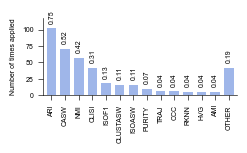

In [95]:
counts = df[df['Metric'].str.lower().isin(bio)]['Metric'].value_counts().dropna()

mask = counts <= 4
main_counts = counts[~mask]
other_sum = counts[mask].sum()

if other_sum > 0:
    other_series = pd.Series({'OTHER': other_sum})
    plot_data = pd.concat([main_counts, other_series])
else:
    plot_data = main_counts

ax = plot_data.plot(kind="bar", width=.7, color='#9fb6e9', figsize=(2.5, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.ylabel("Number of times applied", fontsize=5)

for i, p in enumerate(ax.patches):
    if i == len(ax.patches) - 1:
        ax.annotate(f"{df[df['Metric'].isin(counts[mask].index)]['Method'].nunique() / total_n:.2f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()+ 3), 
                    ha='center', va='center', 
                    xytext=(0, 7), 
                    textcoords='offset points', rotation=90,
                    fontsize=5)
        break

    percentage = f'{p.get_height() / total_n:.2f}'
    ax.annotate(percentage, 
                (p.get_x() + p.get_width() / 2., p.get_height() + 3), 
                ha='center', va='center', 
                xytext=(0, 7), 
                textcoords='offset points', rotation=90,
                fontsize=5)

ax.tick_params(axis='both', labelsize=5, width=.45)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.ylim(0, plot_data.max() * 1.15)
plt.savefig('../publication_figures/bioconservation_survey.svg', dpi=250, bbox_inches='tight')
plt.show()

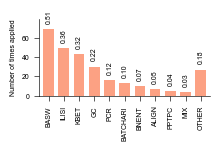

In [96]:
counts = df[df['Metric'].str.lower().isin(batch)]['Metric'].value_counts().dropna()

mask = counts < 4
main_counts = counts[~mask]
other_sum = counts[mask].sum()

if other_sum > 0:
    other_series = pd.Series({'OTHER': other_sum})
    plot_data = pd.concat([main_counts, other_series])
else:
    plot_data = main_counts

ax = plot_data.plot(kind="bar", width=.7, color='#fca183', figsize=(2.2, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.ylabel("Number of times applied", fontsize=5)

for i, p in enumerate(ax.patches):
    if i == len(ax.patches) - 1:
        ax.annotate(f"{df[df['Metric'].isin(counts[mask].index)]['Method'].nunique() / total_n:.2f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()+3), 
                    ha='center', va='center', 
                    xytext=(0, 7), 
                    textcoords='offset points', rotation=90,
                    fontsize=5)
        break

    percentage = f'{p.get_height() / total_n:.2f}'
    ax.annotate(percentage, 
                (p.get_x() + p.get_width() / 2., p.get_height()+3), 
                ha='center', va='center', 
                xytext=(0, 7), 
                textcoords='offset points', rotation=90,
                fontsize=5)

ax.tick_params(axis='both', labelsize=5, width=.45)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.ylim(0, plot_data.max() * 1.15)
plt.savefig('../publication_figures/batch_survey.svg', dpi=250, bbox_inches='tight')
plt.show()

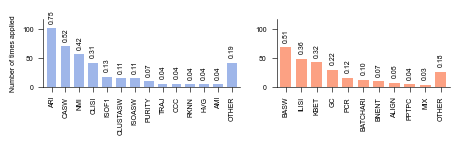

In [97]:
import matplotlib.pyplot as plt
import pandas as pd


fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(4.7, 1.5), sharey=True, gridspec_kw={"width_ratios": [2.5, 2.2]}
)

# =====================================================================
# PLOT 1: Bioconservation Survey
# =====================================================================
counts_bio = (
    df[df["Metric"].str.lower().isin(bio)]["Metric"].value_counts().dropna()
)

mask_bio = counts_bio <= 4
main_counts_bio = counts_bio[~mask_bio]
other_sum_bio = counts_bio[mask_bio].sum()

if other_sum_bio > 0:
    other_series_bio = pd.Series({"OTHER": other_sum_bio})
    plot_data_bio = pd.concat([main_counts_bio, other_series_bio])
else:
    plot_data_bio = main_counts_bio

# Plot on ax1
plot_data_bio.plot(kind="bar", width=0.7, color="#9fb6e9", ax=ax1)
ax1.set_ylabel("Number of times applied", fontsize=5)

for i, p in enumerate(ax1.patches):
    if i == len(ax1.patches) - 1 and other_sum_bio > 0:
        val = (
            df[df["Metric"].isin(counts_bio[mask_bio].index)]["Method"].nunique()
            / total_n
        )
    else:
        val = p.get_height() / total_n

    ax1.annotate(
        f"{val:.2f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 3),
        ha="center",
        va="center",
        xytext=(0, 7),
        textcoords="offset points",
        rotation=90,
        fontsize=5,
    )


# =====================================================================
# PLOT 2: Batch Survey
# =====================================================================
counts_batch = (
    df[df["Metric"].str.lower().isin(batch)]["Metric"].value_counts().dropna()
)

mask_batch = counts_batch < 4
main_counts_batch = counts_batch[~mask_batch]
other_sum_batch = counts_batch[mask_batch].sum()

if other_sum_batch > 0:
    other_series_batch = pd.Series({"OTHER": other_sum_batch})
    plot_data_batch = pd.concat([main_counts_batch, other_series_batch])
else:
    plot_data_batch = main_counts_batch

# Plot on ax2
plot_data_batch.plot(kind="bar", width=0.7, color="#fca183", ax=ax2)

for i, p in enumerate(ax2.patches):
    if i == len(ax2.patches) - 1 and other_sum_batch > 0:
        val = (
            df[df["Metric"].isin(counts_batch[mask_batch].index)]["Method"].nunique()
            / total_n
        )
    else:
        val = p.get_height() / total_n

    ax2.annotate(
        f"{val:.2f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 3),
        ha="center",
        va="center",
        xytext=(0, 7),
        textcoords="offset points",
        rotation=90,
        fontsize=5,
    )


# =====================================================================
# GLOBAL STYLING & SAVING
# =====================================================================
# Clean up spines and ticks for both axes
for ax in [ax1, ax2]:
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", labelsize=5, width=0.45)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)

# Dynamically set ylim based on the max value across both datasets
max_y = max(plot_data_bio.max(), plot_data_batch.max())
plt.ylim(0, max_y * 1.15)
ax2.yaxis.set_tick_params(labelleft=True)
# Adjust spacing so they look like distinct individual plots but align perfectly
plt.tight_layout()

# Save combined figure
plt.savefig(
    "../publication_figures/combined_survey.svg", dpi=250, bbox_inches="tight"
)
plt.show()

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/metacell_env/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/metacell_env/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to p

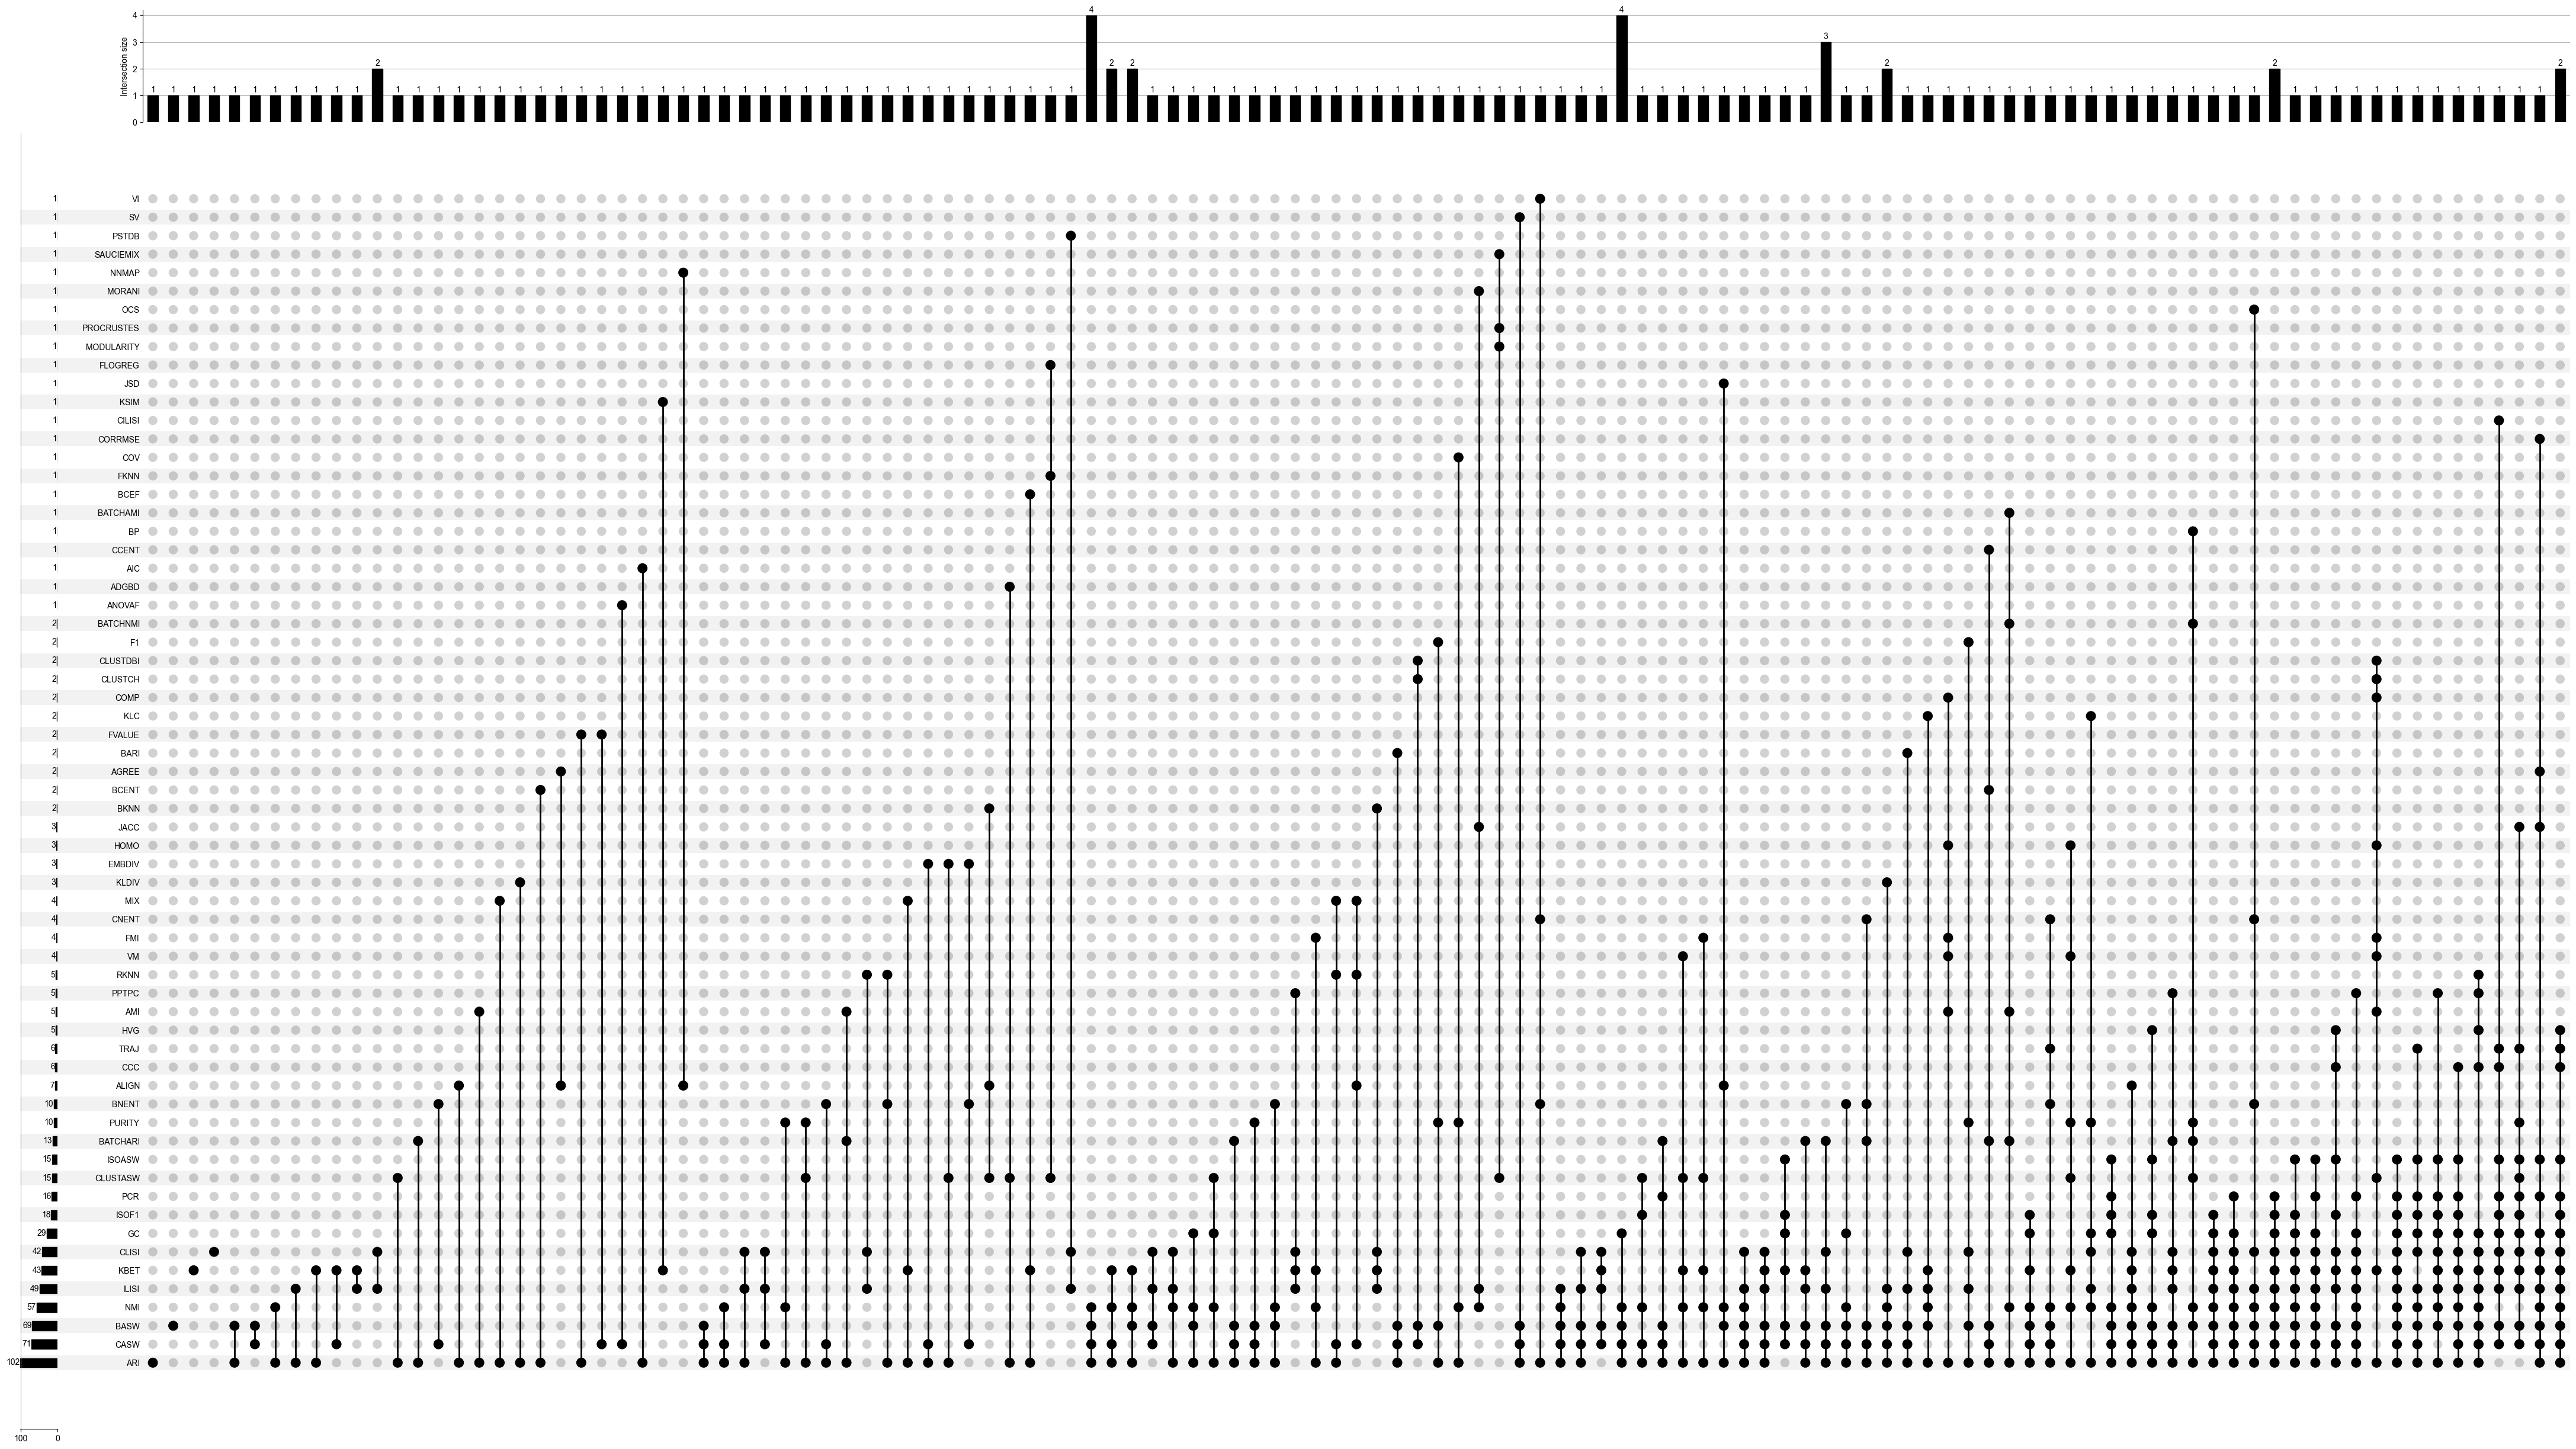

In [98]:
contents = df.groupby('Metric')['Method'].unique().apply(list).to_dict()
data = from_contents(contents)
UpSet(data, show_counts=True).plot()
plt.show()

In [99]:
data

id
ADGBD AGREE AIC   ALIGN AMI   ANOVAF ARI   BARI  BASW  BATCHAMI BATCHARI BATCHNMI BCEF  BCENT BKNN  BNENT BP    CASW  CCC   CCENT CILISI CLISI CLUSTASW CLUSTCH CLUSTDBI CNENT COMP  CORRMSE COV   EMBDIV F1    FKNN  FLOGREG FMI   FVALUE GC    HOMO  HVG   ILISI ISOASW ISOF1 JACC  JSD   KBET  KLC   KLDIV KSIM  MIX   MODULARITY MORANI NMI   NNMAP OCS   PCR   PPTPC PROCRUSTES PSTDB PURITY RKNN  SAUCIEMIX SV    TRAJ  VI    VM                
True  False False False False False  True  False False False    False    False    False False False False False False False False False  False True     False   False    False False False   False False  False False False   False False  False False False False False  False False False False False False False False False      False  False False False False False False      False False  False False     False False False False    scInsight
False True  False True  False False  False False False False    False    False    False False False False False False False False False  False False    False   False    False False False   False False  False False False   False False  False False False False False  False False False False False False False False False      False  False False False False False False      False False  False False     False False False False        LIGER
                  False False False  True  False True  False    False    False    False False False False False True  False False False  True  False    False   False    False False True    False False  False False False   False False  True  False False True  True   False True  False True  False False False False False      False  True  False False True  False False      False False  False False     False False False False  YiBenchmark
      False True  False False False  True  False False False    False    False    False False False False False False False False False  False False    False   False    False False False   False False  False False False   False False  False False False False False  False False False False False False False False False      False  False False False False False False      False False  False False     False False False False      NewWave
            False True  False False  False False False False    False    False    False False False False False True  False False False  False False    False   False    False False False   False False  False False False   False False  False False False False False  False False False False False False False True  False      False  False False False False False False      False False  True  False     False False False False          CCA
...                                                                                                                                                                                                                                                                                                                                                                                                                                                ...
                  False False False  False False False False    False    False    False False False False False False False False False  False True     False   False    False False False   False False  False False False   False False  False False False False False  False False False False False False False False True       False  False False False False False True       False False  False True      False False False False       SAUCIE
                                                                                                                                               False    False   False    False False False   False False  False False False   False False  False False False True  False  False False False True  False False False False False      False  False False False False False False      False False  False False     False False False False        BEENE
                                              

In [100]:
df['Method'].nunique()

136

In [101]:
benchmark_info = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=4)

In [102]:
# set(df['Method'].unique()).difference(benchmark_info['Benchmark'])

# set(benchmark_info['Benchmark']).difference(df['Method'].unique())

len(set(benchmark_info['Benchmark']).intersection(df['Method'].unique()))

136

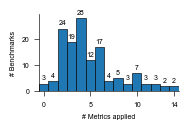

In [104]:
counts = df.groupby('Method')['Metric'].nunique()

fig, ax = plt.subplots(figsize=(1.8, 1))

counts, bins, patches = ax.hist(
    counts, 
    bins=range(counts.min(), counts.max() + 2), 
    edgecolor='black',
    linewidth=0.45,
    align='left'
)

for count, rect in zip(counts, patches):
    height = rect.get_height()

    ax.text(
        rect.get_x() + rect.get_width() / 2,
        height + 1,
        int(height),
        ha='center',
        va='bottom',
        fontsize=5
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=5, width=.45)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xlim(-0.5, 14.5)
plt.xticks([0, 5, 10, 14])

plt.ylabel("# Benchmarks", fontsize=5)
plt.xlabel("# Metrics applied", fontsize=5)
plt.savefig('../publication_figures/num_metrics_applied.svg', dpi=300, bbox_inches='tight')
plt.show()

In [105]:
counts = df.groupby('Method')['Metric'].nunique().reset_index()
counts = pd.merge(counts, benchmark_info, left_on='Method', right_on='Benchmark')

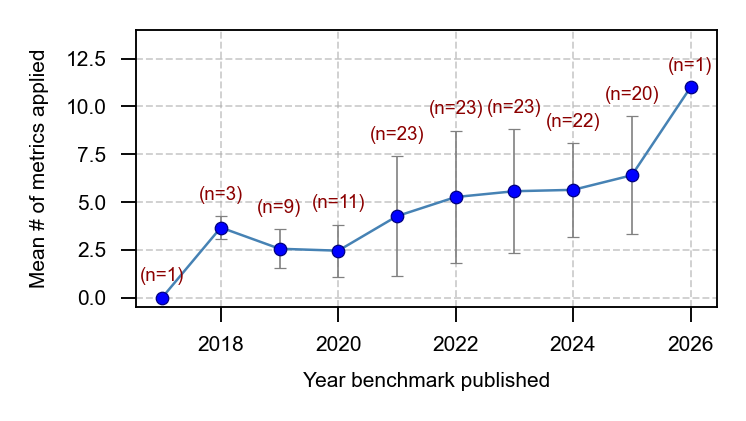

In [113]:
stats = counts.groupby('Year published')['Metric'].agg(['mean', 'std', 'count']).reset_index()

with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(2.5, 1.2))

    # 2. Plot the line and error bars
    # We capture the line to use its coordinates for labeling
    ax.errorbar(stats['Year published'], 
                stats['mean'], 
                yerr=stats['std'], 
                fmt='-o', 
                capsize=1.5,
                capthick=0.4,
                ecolor='gray',
                alpha=1,
                lw=0.6,
                elinewidth=0.4,
                markersize=3,           # was defaulting to ~6-8
                markerfacecolor='blue',
                markeredgewidth=0.3,
                markeredgecolor='navy',
                color='steelblue',
                label='Mean ± Std Dev')

    # 3. Annotate the number of data points (n=...)
    for i, row in stats.iterrows():
        y_top = row['mean'] + (row['std'] if pd.notna(row['std']) else 0)
        ax.annotate(f"(n={int(row['count'])})", 
                    xy=(row['Year published'], y_top), 
                    xytext=(0, 3),              # small fixed offset in points
                    textcoords="offset points", 
                    ha='center', 
                    va='bottom',
                    fontsize=4.5, 
                    fontweight='bold',
                    color='darkred')


    # 3. Formatting
    # plt.title('Average # Metric per Year with Variance (Std Dev) Bars')
    plt.xlabel('Year benchmark published', fontsize=5)
    plt.ylabel('Mean # of metrics applied', fontsize=5)
    plt.grid(True, linestyle='--', alpha=0.6, linewidth=0.45)
    ax.tick_params(axis='both', labelsize=5, width=.45)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.ylim(-.5, 14)
    plt.savefig('../publication_figures/metrics_mean.svg', dpi=250, bbox_inches='tight')
    plt.show()
    # Save or display

## Concordance between metrics & datasets used when comparing methods

In [160]:
metrics = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=0)
datasets = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=1)
comparisons = pd.read_excel('../results/spreadsheets/Metrics_Final.xlsx', sheet_name=2)

datasets['Paper'] = datasets['Dataset First Author'] + '_' + datasets['Dataset Year'].fillna(0).astype(int).astype(str) +'_'+ datasets['Dataset Journal'].fillna('')

In [161]:
comparisons.drop('Notes', inplace=True, axis=1)
metrics.drop("Notes", inplace=True, axis=1)

In [162]:
comp_metrics = comparisons.merge(
    metrics, 
    left_on="Comparison", 
    right_on="Method", 
    suffixes=('', '_comp')
).drop(columns="Method_comp")

analysis = comp_metrics.merge(
    metrics, 
    on=["Method", "Metric"], 
    how="left", 
    indicator="match"
)

analysis["uses_same_metric"] = analysis["match"] == "both"

In [163]:
share_some = analysis.groupby(['Method', 'Comparison'])['uses_same_metric'].apply(lambda x: x.any()).reset_index()
share_some['uses_same_metric'].sum(), len(share_some), share_some['uses_same_metric'].sum() /len(share_some)

(377, 597, 0.6314907872696818)

In [164]:
share_all = analysis.groupby(['Method', 'Comparison'])['uses_same_metric'].apply(lambda x: x.all()).reset_index()
share_all['uses_same_metric'].sum(), len(share_some),share_all['uses_same_metric'].sum() /  len(share_some)

(66, 597, 0.11055276381909548)

In [165]:
overlap_rate = analysis.groupby("Method")["uses_same_metric"].mean()
missed_metrics = analysis[analysis["uses_same_metric"] == False]["Metric"].value_counts()

overlap_rate, missed_metrics

(Method
 AIF        0.416667
 BATMAN     0.272727
 BBKNN      0.000000
 BDACL      0.575000
 BEENE      0.200000
              ...   
 scVAE      0.250000
 scVI       0.666667
 sciLaMa    0.666667
 sysVI      0.200000
 tGPT       0.291667
 Name: uses_same_metric, Length: 129, dtype: float64,
 Metric
 BNENT         143
 ALIGN         126
 CASW          122
 RKNN           96
 MIX            84
 CLISI          71
 ANOVAF         62
 ILISI          61
 ARI            44
 AGREE          42
 BASW           42
 KBET           40
 NMI            34
 CLUSTASW       16
 KLDIV          15
 BATCHARI       12
 BKNN           11
 PPTPC          10
 GC              8
 SAUCIEMIX       6
 BARI            6
 EMBDIV          6
 PROCRUSTES      6
 ISOASW          6
 MODULARITY      6
 ISOF1           5
 AMI             5
 BCENT           4
 PCR             4
 FMI             3
 NNMAP           3
 PURITY          3
 KSIM            3
 CCC             2
 CLUSTDBI        2
 ADGBD           2
 CNENT         

In [36]:
datasets

,Method,Dataset First Author,Dataset Year,Dataset Journal,Notes
0,AIF,Villani,2017.0,Science,Human blood dendritic cells
1,AIF,Muraro,2016.0,Cell Systems,NaN
2,AIF,Segerstolpe,2016.0,Cell Metabolism,NaN
3,AIF,Xin,2016.0,Cell Metabolism,NaN
4,AIF,Wang,2016.0,Diabetes,NaN
...,...,...,...,...,...
1023,scTrans,Tabula Muris Consortium,2018.0,Nature,NaN
1024,scTrans,Baron,2016.0,Cell Systems,NaN
1025,scTrans,Ding,2020.0,Nature Biotechnology,NaN
1026,scTrans,Le,2020.0,Immunity,NaN


In [166]:
comp_metrics = comparisons.merge(
    datasets[['Method', 'Paper']], 
    left_on="Comparison", 
    right_on="Method", 
    suffixes=('', '_comp')
).drop(columns="Method_comp")

analysis = comp_metrics.merge(
    datasets[['Method', 'Paper']], 
    on=["Method", "Paper"], 
    how="left", 
    indicator="match"
)

analysis["uses_same_metric"] = analysis["match"] == "both"

In [167]:
analysis

,Method,Comparison,Paper,match,uses_same_metric
0,Scanorama,MNN,Haghverdi_2018_Nature Biotechnology,left_only,False
1,Scanorama,MNN,Nestorowa_2016_Blood,both,True
2,Scanorama,MNN,Paul_2015_Cell,both,True
3,Scanorama,MNN,Muraro_2016_Cell Systems,both,True
4,Scanorama,MNN,Grun_2016_Cell Stem Cell,both,True
...,...,...,...,...,...
5246,scTrans,DESC,Muraro_2016_Cell Systems,left_only,False
5247,scTrans,DESC,Kang_2018_Nature Biotechnology,left_only,False
5248,scTrans,DESC,Paul_2015_Cell,left_only,False
5249,scTrans,DESC,Li_2020_Nature Communications,left_only,False


In [168]:
share_some = analysis.groupby(['Method', 'Comparison'])['uses_same_metric'].apply(lambda x: x.any()).reset_index()
share_some['uses_same_metric'].sum(), len(share_some), share_some['uses_same_metric'].sum() /len(share_some)

(374, 597, 0.626465661641541)

In [169]:
share_all = analysis.groupby(['Method', 'Comparison'])['uses_same_metric'].apply(lambda x: x.all()).reset_index()
share_all['uses_same_metric'].sum(), len(share_some),share_all['uses_same_metric'].sum() /  len(share_some)

(7, 597, 0.011725293132328308)

In [170]:
analysis[analysis.Method == 'scIB']

,Method,Comparison,Paper,match,uses_same_metric
4807,scIB,MNN,Haghverdi_2018_Nature Biotechnology,left_only,False
4808,scIB,MNN,Nestorowa_2016_Blood,left_only,False
4809,scIB,MNN,Paul_2015_Cell,left_only,False
4810,scIB,MNN,Muraro_2016_Cell Systems,both,True
4811,scIB,MNN,Grun_2016_Cell Stem Cell,left_only,False
...,...,...,...,...,...
4897,scIB,DESC,Muraro_2016_Cell Systems,both,True
4898,scIB,DESC,Kang_2018_Nature Biotechnology,left_only,False
4899,scIB,DESC,Paul_2015_Cell,left_only,False
4900,scIB,DESC,Li_2020_Nature Communications,left_only,False
